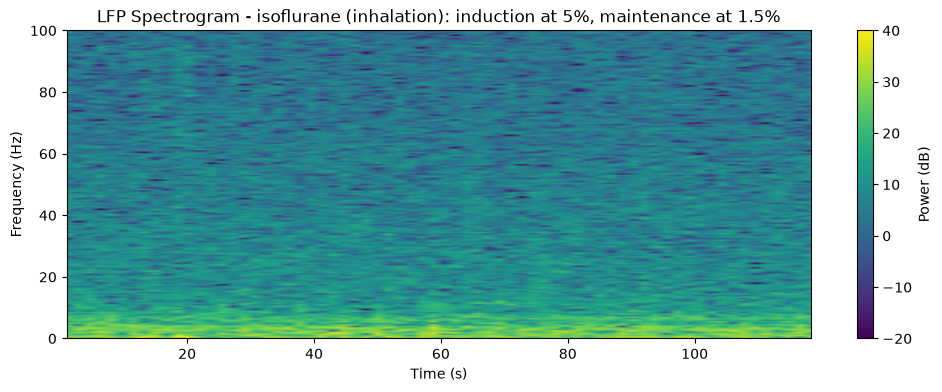

In [1]:
from pynwb import NWBHDF5IO
from scipy import signal
import matplotlib.pyplot as plt
import numpy as np

io = NWBHDF5IO('../../data/raw/688277-20230921-v001.nwb', mode='r')
nwbfile = io.read()

probe = 'probeB'  # or probeC, probeD, probeF
LFP = nwbfile.acquisition['LFP'][f'ElectricalSeries{probe}']
data = LFP.data[:, 0] * LFP.conversion * 1e6  # µV, channel 0
timestamps = LFP.timestamps[:]
fs = 1 / np.mean(np.diff(timestamps[:1000]))

# Downsample for spectrogram
downsample = 4
data_ds = signal.decimate(data, downsample)
fs_ds = fs / downsample

# Spectrogram (first 120 sec)
f, t, Sxx = signal.spectrogram(data_ds[:int(120*fs_ds)], fs=fs_ds, nperseg=int(fs_ds*2))
plt.figure(figsize=(12, 4))
plt.pcolormesh(t, f, 10*np.log10(Sxx), shading='gouraud', vmin=-20, vmax=40)
plt.ylim(0, 100)
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Power (dB)')
plt.title(f'LFP Spectrogram - {nwbfile.pharmacology}')
io.close()

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pynwb import NWBHDF5IO

DATA_DIR = Path('../../data/raw')
FILES = sorted(DATA_DIR.glob('*.nwb'))
print(FILES)

[PosixPath('../../data/raw/688277-20230921-v001.nwb'), PosixPath('../../data/raw/692644-20230907-v001.nwb')]


In [3]:
for f in FILES:
    with NWBHDF5IO(f, mode='r') as io:
        nwb = io.read()
        print('=' * 60)
        print(f.name)
        print('Drugs:', nwb.pharmacology)
        print('Probes:', [k for k in nwb.electrode_groups.keys() if 'probe' in k])
        print('Has isoflurane signal:', 'isoflurane_level' in nwb.acquisition)
        print(nwb.epochs.to_dataframe() if nwb.epochs is not None else 'No epochs')

688277-20230921-v001.nwb
Drugs: isoflurane (inhalation): induction at 5%, maintenance at 1.5%
Probes: ['probeB', 'probeD', 'probeF']
Has isoflurane signal: True
No epochs
692644-20230907-v001.nwb
Drugs: 1st injection: saline (0.01 mL/g, i.p.); 2nd injection: psilocybin (1 mg/kg, i.p.)
Probes: ['probeB', 'probeD', 'probeF']
Has isoflurane signal: False
    start_time  stop_time                                        tags
id                                                                   
0       2462.0     2650.0    [1st injection, saline, 0.01 mL/g, i.p.]
1       3148.0     3388.0  [2nd injection, psilocybin, 1 mg/kg, i.p.]


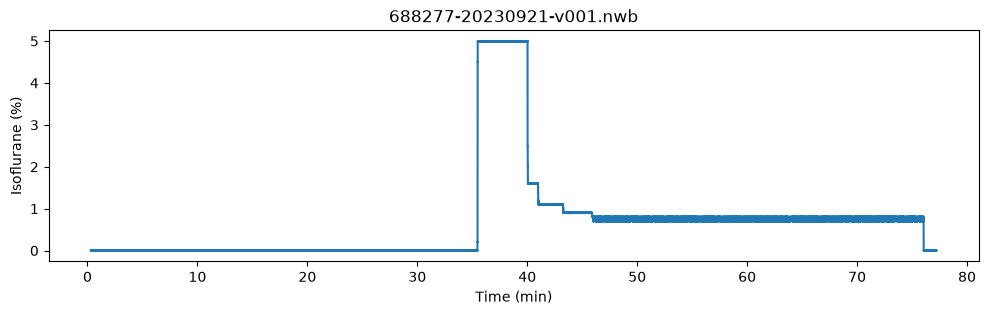

In [4]:
with NWBHDF5IO(FILES[0], mode='r') as io:
    nwb = io.read()
    if 'isoflurane_level' in nwb.acquisition:
        iso = nwb.acquisition['isoflurane_level']
        level = iso.data[:]
        t_iso = np.arange(len(level)) / iso.rate + iso.starting_time
        plt.figure(figsize=(12, 3))
        plt.plot(t_iso / 60, level)
        plt.xlabel('Time (min)')
        plt.ylabel('Isoflurane (%)')
        plt.title(FILES[0].name)
        plt.show()

In [5]:
def load_lfp(nwb, probe, t_start, t_stop, channels):
    es = nwb.acquisition['LFP'][f'ElectricalSeries{probe}']
    ts = es.timestamps[:]
    i0, i1 = np.searchsorted(ts, [t_start, t_stop])
    data = es.data[i0:i1, :][:, channels] * es.conversion * 1e6
    fs = 1 / np.mean(np.diff(ts[:1000]))
    return ts[i0:i1], data, fs

def plot_condition(nwb, probe, t_start, t_stop, channels, label):
    t, data, fs = load_lfp(nwb, probe, t_start, t_stop, channels)
    data = data - data.mean(axis=0)
    regions = nwb.acquisition['LFP'][f'ElectricalSeries{probe}'].electrodes.to_dataframe().location.values

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

    offset = 500
    for k, ch in enumerate(channels):
        ax1.plot(t - t[0], data[:, k] + k * offset, lw=0.5)
    ax1.set_yticks([k * offset for k in range(len(channels))])
    ax1.set_yticklabels([f'ch {ch} ({regions[ch]})' for ch in channels])
    ax1.set_xlabel('Time (s)')
    ax1.set_title(f'{label}: raw LFP, {probe}')

    ds = 4
    x = signal.decimate(data[:, 0], ds)
    f, tt, Sxx = signal.spectrogram(x, fs=fs / ds, nperseg=int(fs / ds * 2))
    im = ax2.pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading='gouraud', vmin=-20, vmax=40)
    ax2.set_ylim(0, 100)
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Frequency (Hz)')
    ax2.set_title(f'{label}: spectrogram, ch {channels[0]}')
    fig.colorbar(im, ax=ax2, label='Power (dB)')
    plt.show()

In [6]:
with NWBHDF5IO(FILES[1], mode='r') as io:
    ts = io.read().acquisition['LFP']['ElectricalSeriesprobeB'].timestamps
    print('Recording ends at', ts[-1] / 60, 'min')

Recording ends at 98.08260258715121 min


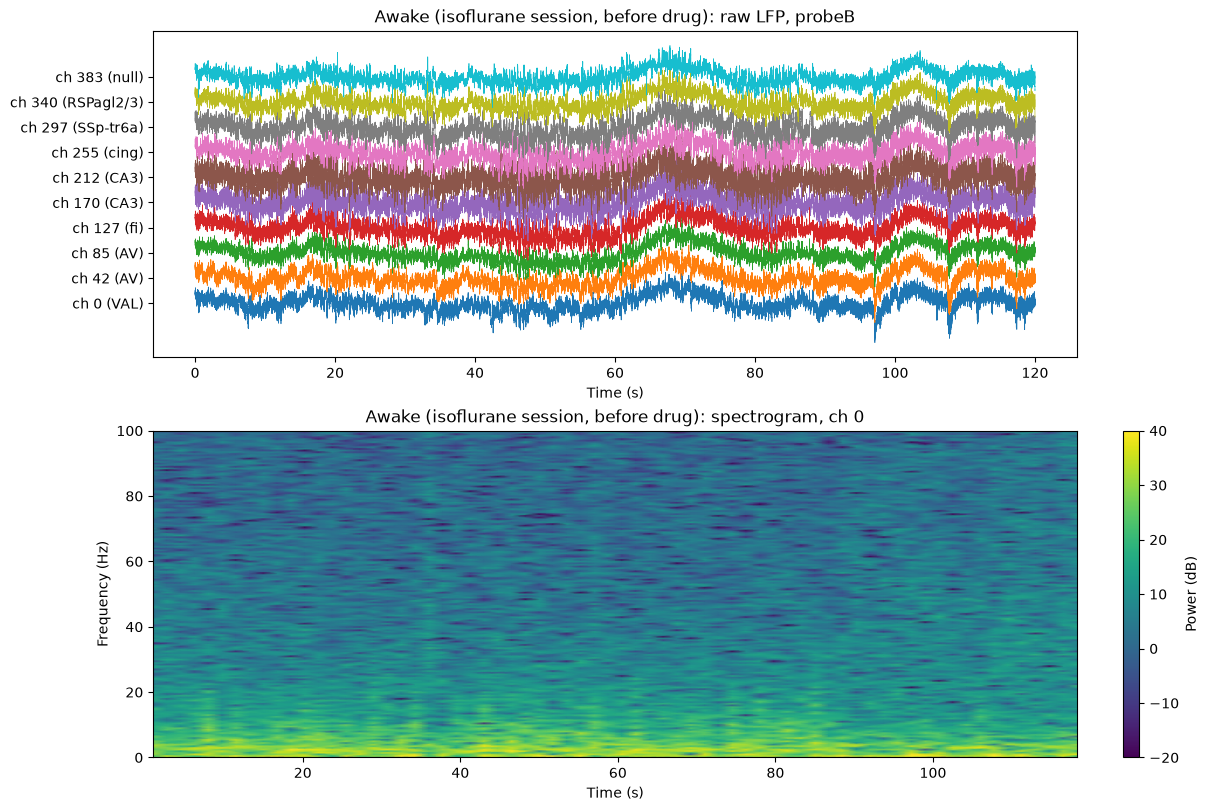

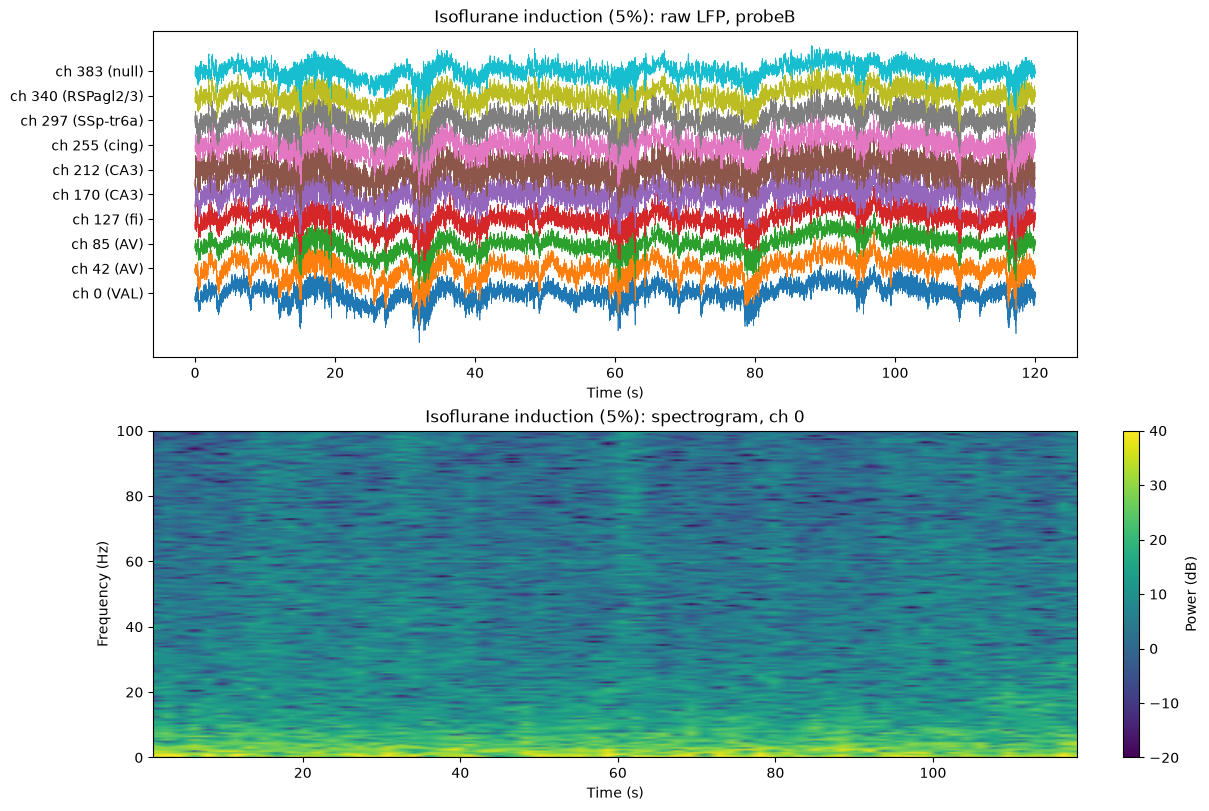

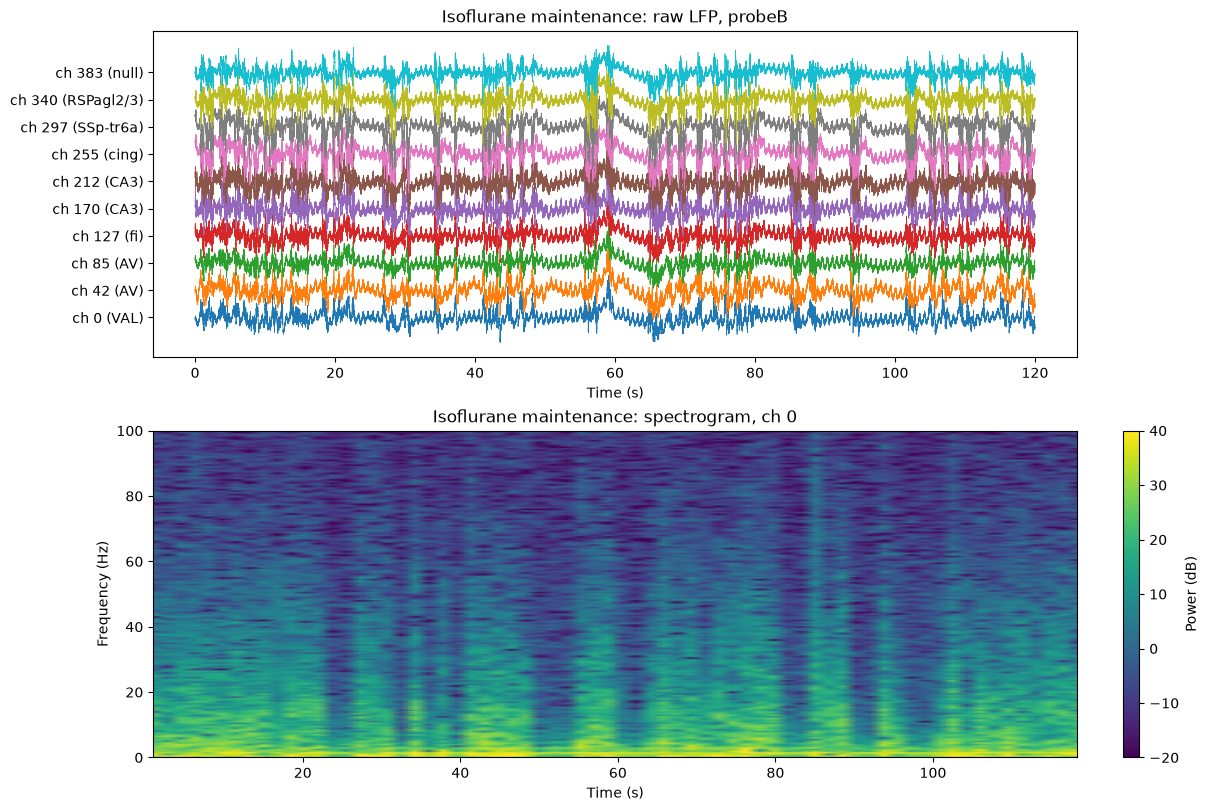

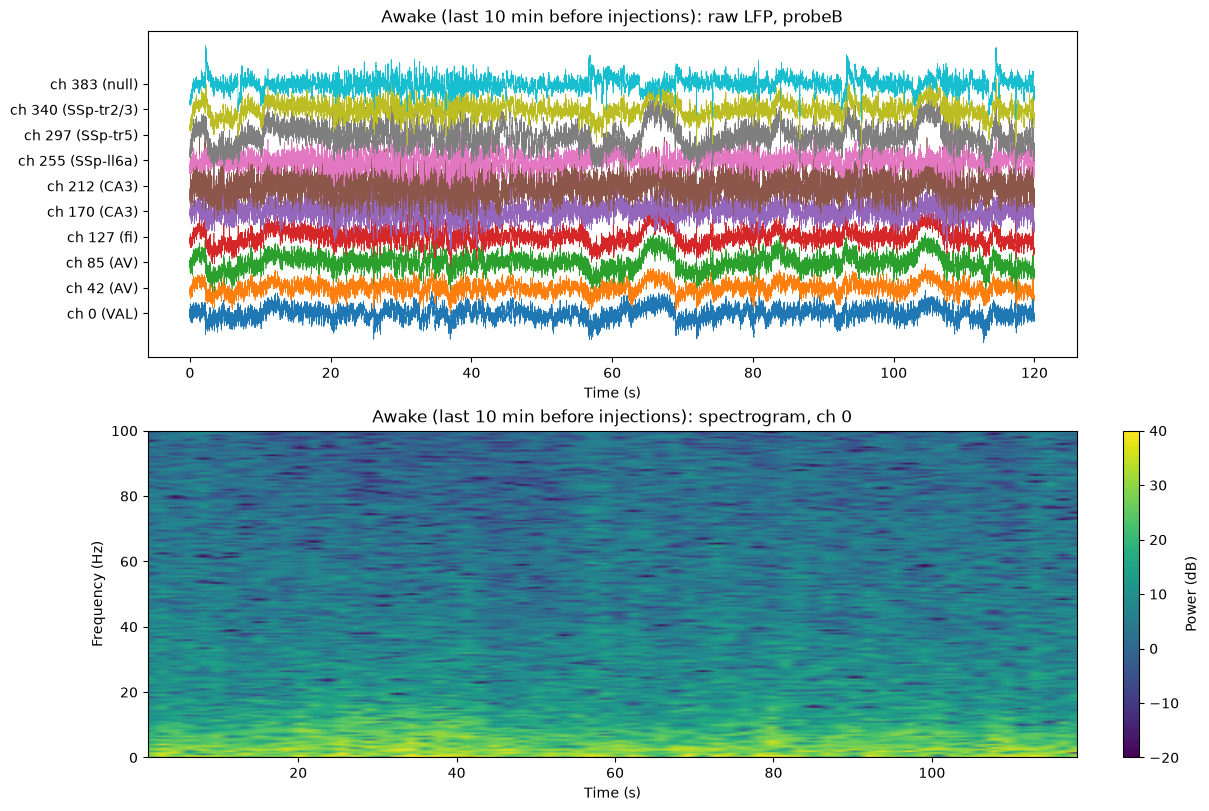

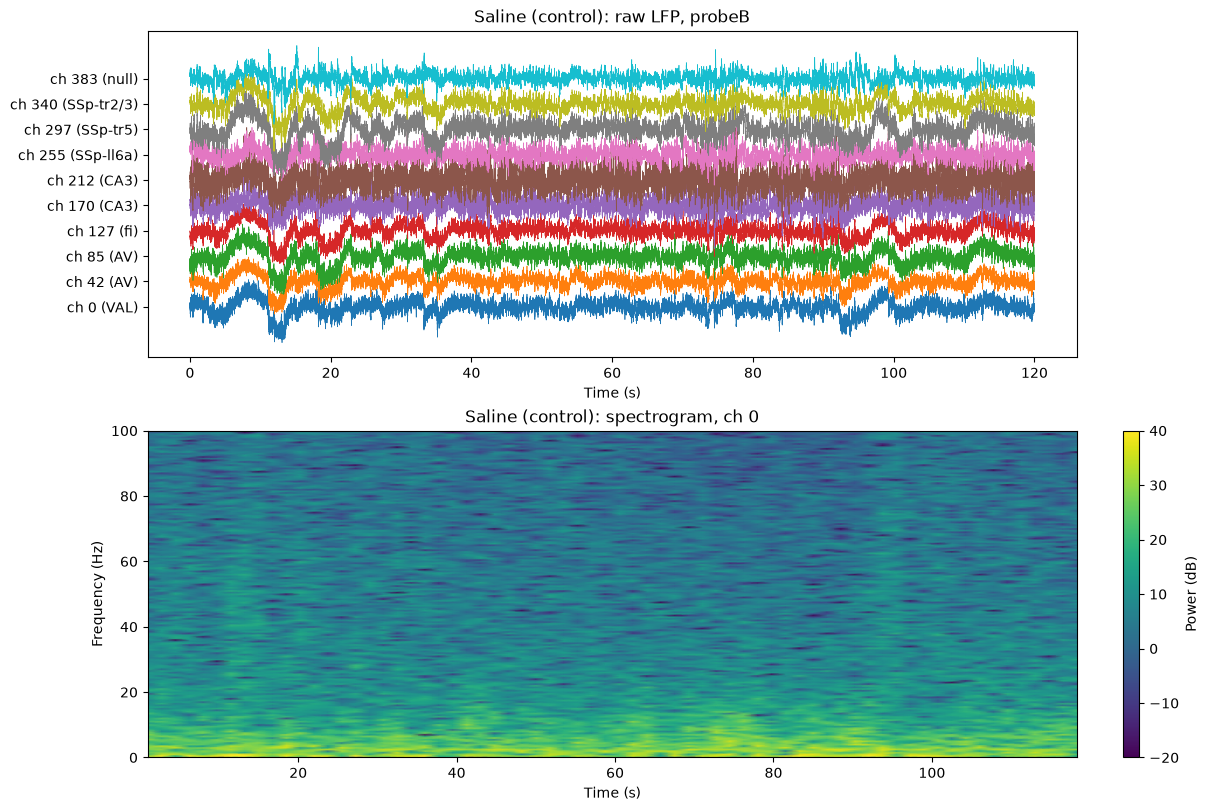

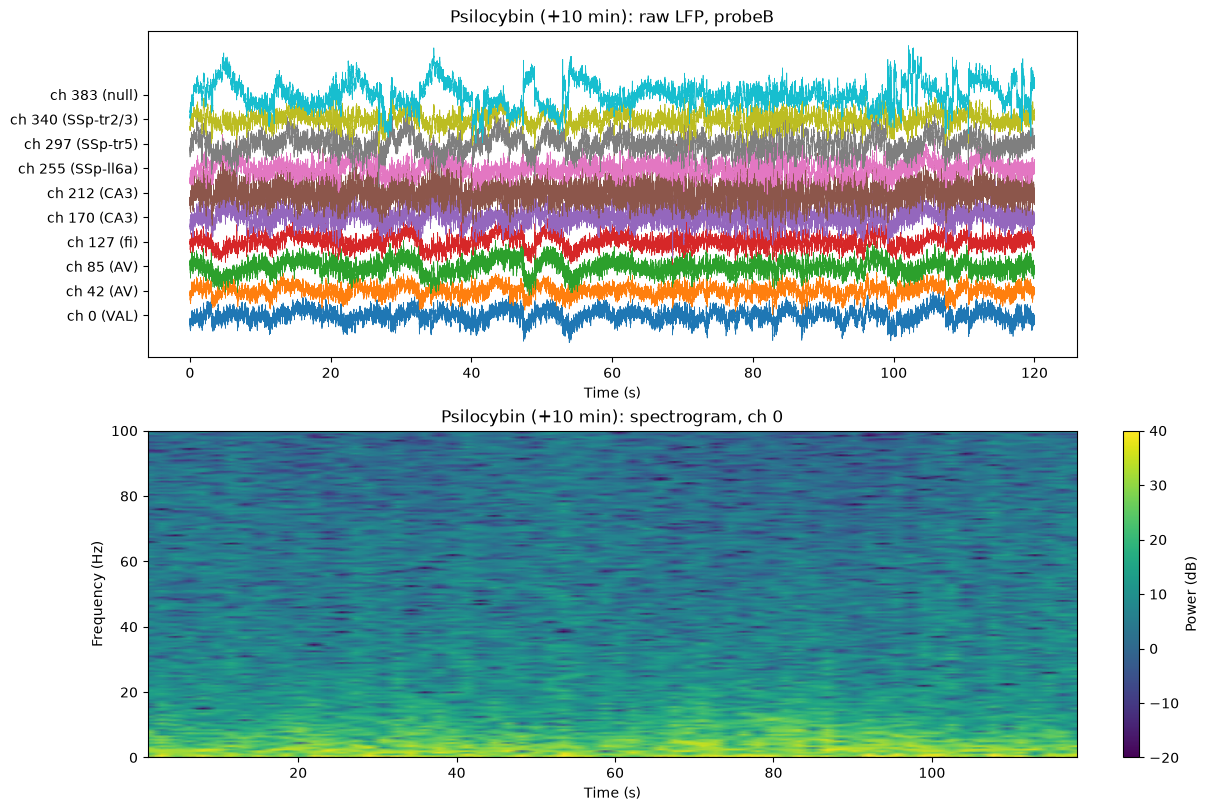

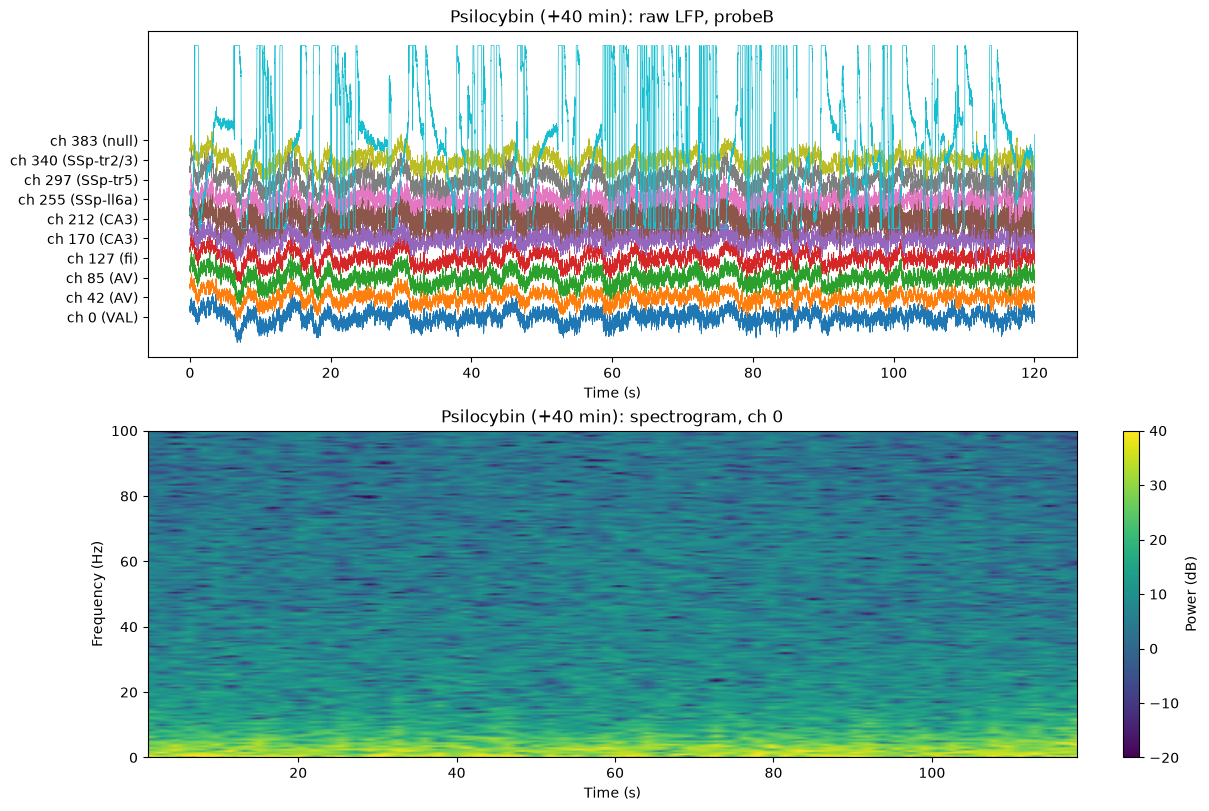

In [7]:
PROBE = 'probeB'
WINDOW = 120  # seconds per plot

# (file index, start time in seconds, label)
CONDITIONS = [
    (0,  600, 'Awake (isoflurane session, before drug)'),
    (0, 2200, 'Isoflurane induction (5%)'),
    (0, 3600, 'Isoflurane maintenance'),
    (1, 2200, 'Awake (last 10 min before injections)'),
    (1, 2800, 'Saline (control)'),
    (1, 3750, 'Psilocybin (+10 min)'),
    (1, 5548, 'Psilocybin (+40 min)'),
]

for file_idx, t0, label in CONDITIONS:
    with NWBHDF5IO(FILES[file_idx], mode='r') as io:
        nwb = io.read()
        n_ch = nwb.acquisition['LFP'][f'ElectricalSeries{PROBE}'].data.shape[1]
        channels = list(np.linspace(0, n_ch - 1, 10).astype(int))
        plot_condition(nwb, PROBE, t0, t0 + WINDOW, channels, label)

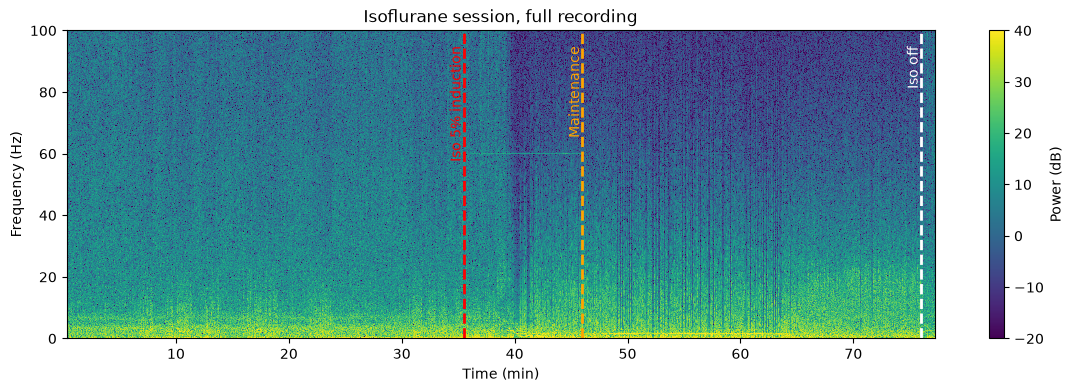

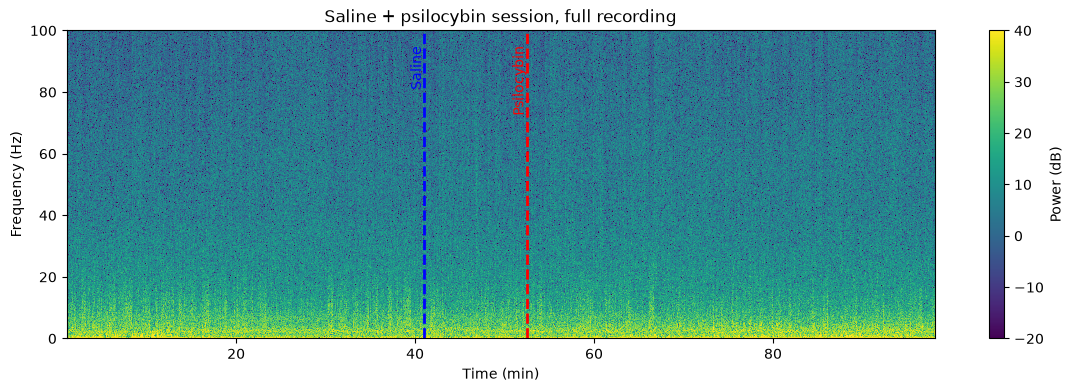

In [8]:
def full_session_spectrogram(file_idx, probe, title, markers):
    with NWBHDF5IO(FILES[file_idx], mode='r') as io:
        nwb = io.read()
        es = nwb.acquisition['LFP'][f'ElectricalSeries{probe}']
        ts = es.timestamps[:]
        fs = 1 / np.mean(np.diff(ts[:1000]))
        x = es.data[:, 0] * es.conversion * 1e6   # one channel, whole session

    ds = 10
    x = signal.decimate(x, ds)
    f, tt, Sxx = signal.spectrogram(x, fs=fs / ds, nperseg=int(fs / ds * 4))
    tt = (tt + ts[0]) / 60   # minutes

    plt.figure(figsize=(14, 4))
    plt.pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading='auto', vmin=-20, vmax=40)
    for t_min, name, color in markers:
        plt.axvline(t_min, color=color, ls='--', lw=2)
        plt.text(t_min, 95, name, color=color, rotation=90, va='top', ha='right')
    plt.ylim(0, 100)
    plt.xlabel('Time (min)')
    plt.ylabel('Frequency (Hz)')
    plt.title(title)
    plt.colorbar(label='Power (dB)')
    plt.show()

full_session_spectrogram(0, 'probeB', 'Isoflurane session, full recording', [
    (35.5, 'Iso 5% induction', 'red'),
    (46,   'Maintenance', 'orange'),
    (76,   'Iso off', 'white'),
])

full_session_spectrogram(1, 'probeB', 'Saline + psilocybin session, full recording', [
    (2462 / 60, 'Saline', 'blue'),
    (3148 / 60, 'Psilocybin', 'red'),
])

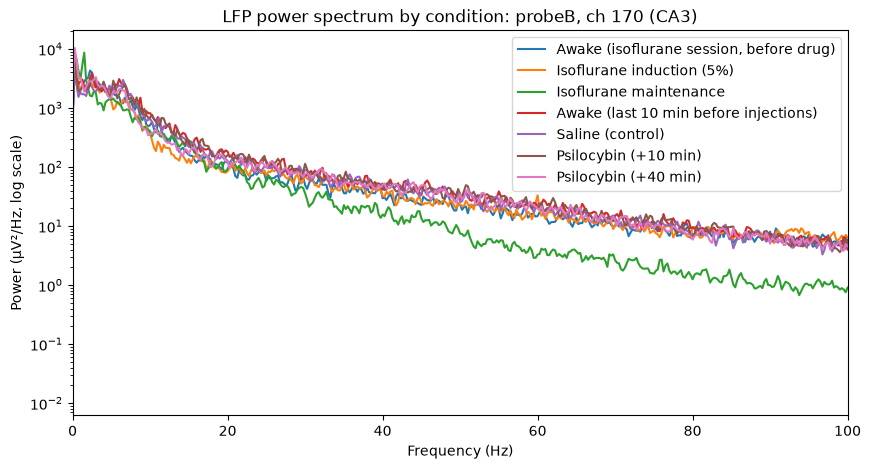

In [9]:
CA3_CH = 170   # CA3 (hippocampus) in both files

plt.figure(figsize=(10, 5))
for file_idx, t0, label in CONDITIONS:
    with NWBHDF5IO(FILES[file_idx], mode='r') as io:
        nwb = io.read()
        _, data, fs = load_lfp(nwb, PROBE, t0, t0 + WINDOW, [CA3_CH])
    f, pxx = signal.welch(data[:, 0], fs=fs, nperseg=int(fs * 4))
    plt.semilogy(f, pxx, label=label)

plt.xlim(0, 100)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power (µV²/Hz, log scale)')
plt.title(f'LFP power spectrum by condition: {PROBE}, ch {CA3_CH} (CA3)')
plt.legend()
plt.show()


## Observations
- **Isoflurane maintenance** shows a burst-suppression-like pattern:
  broadband bursts alternating with quiet periods.
- **Isoflurane induction** looks transitional, with larger and more
  synchronized slow fluctuations in the taces, than awake.
- **Awake vs. saline** look similar.
- **Psilocybin:** No clear psilocybin effect is visible here. A longer window, a later
  time point, or other channels/regions may show differences.
- Low frequencies are strongest in every condition, which is normal for LFP.